In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv('Travel.csv')

In [3]:
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [4]:
df.shape

(4888, 20)

In [5]:
df.describe()

,CustomerID,ProdTaken,Age,CityTier,DurationOfPitch,NumberOfPersonVisiting,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,MonthlyIncome
count,4888.000000,4888.000000,4662.000000,4888.000000,4637.000000,4888.000000,4843.000000,4862.000000,4748.000000,4888.000000,4888.000000,4888.000000,4822.000000,4655.000000
mean,202443.500000,0.188216,37.622265,1.654255,15.490835,2.905074,3.708445,3.581037,3.236521,0.290917,3.078151,0.620295,1.187267,23619.853491
std,1411.188388,0.390925,9.316387,0.916583,8.519643,0.724891,1.002509,0.798009,1.849019,0.454232,1.365792,0.485363,0.857861,5380.698361
min,200000.000000,0.000000,18.000000,1.000000,5.000000,1.000000,1.000000,3.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1000.000000
25%,201221.750000,0.000000,31.000000,1.000000,9.000000,2.000000,3.000000,3.000000,2.000000,0.000000,2.000000,0.000000,1.000000,20346.000000
50%,202443.500000,0.000000,36.000000,1.000000,13.000000,3.000000,4.000000,3.000000,3.000000,0.000000,3.000000,1.000000,1.000000,22347.000000
75%,203665.250000,0.000000,44.000000,3.000000,20.000000,3.000000,4.000000,4.000000,4.000000,1.000000,4.000000,1.000000,2.000000,25571.000000
max,204887.000000,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,5.000000,1.000000,3.000000,98678.000000


In [6]:
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [7]:
df.dtypes

CustomerID                    int64
ProdTaken                     int64
Age                         float64
TypeofContact                   str
CityTier                      int64
DurationOfPitch             float64
Occupation                      str
Gender                          str
NumberOfPersonVisiting        int64
NumberOfFollowups           float64
ProductPitched                  str
PreferredPropertyStar       float64
MaritalStatus                   str
NumberOfTrips               float64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting    float64
Designation                     str
MonthlyIncome               float64
dtype: object

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['ProdTaken'].value_counts()

ProdTaken
0    3968
1     920
Name: count, dtype: int64

In [10]:
df['Gender'].value_counts()

Gender
Male       2916
Female     1817
Fe Male     155
Name: count, dtype: int64

In [11]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married      2340
Divorced      950
Single        916
Unmarried     682
Name: count, dtype: int64

In [12]:
df['Gender']=df['Gender'].replace('Fe Male','Female')

In [13]:
df['Gender'].value_counts()

Gender
Male      2916
Female    1972
Name: count, dtype: int64

In [14]:
df['MaritalStatus']=df['MaritalStatus'].replace('Single','Unmarried')

In [15]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married      2340
Unmarried    1598
Divorced      950
Name: count, dtype: int64

In [16]:
# removien all the null valuewds

In [17]:

features_with_na=[feature for feature in df.columns if df[feature].isnull().sum()>=1]

In [18]:
features_with_na

['Age',
 'TypeofContact',
 'DurationOfPitch',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [19]:
df[features_with_na].columns

Index(['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting',
       'MonthlyIncome'],
      dtype='str')

In [20]:
col =['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting',
       'MonthlyIncome']

In [21]:
# access only numerical colum=nms

In [22]:
df_numeric=df[features_with_na][col].select_dtypes('float64','int64')

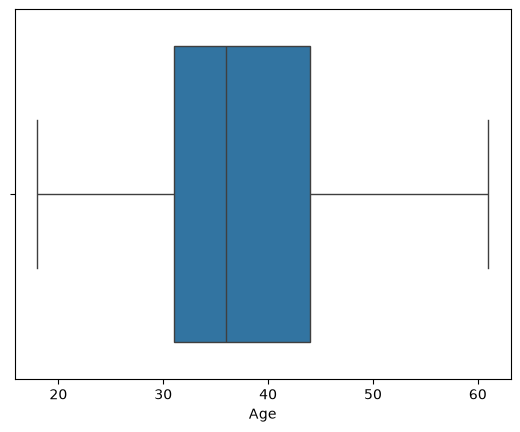

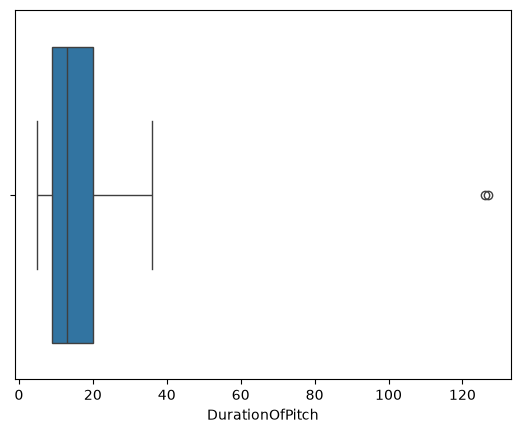

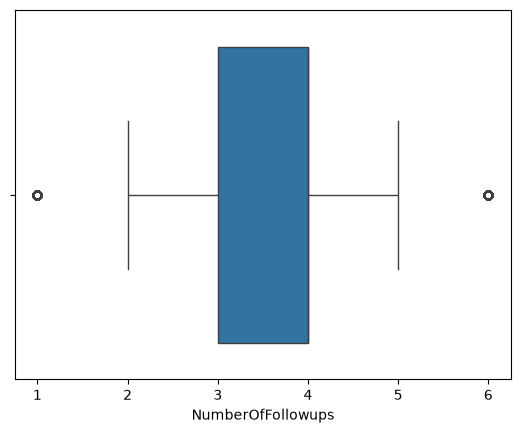

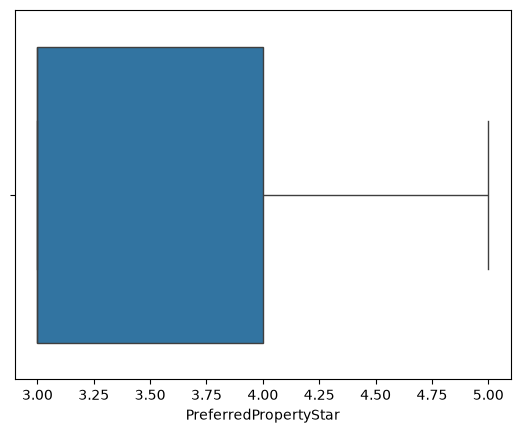

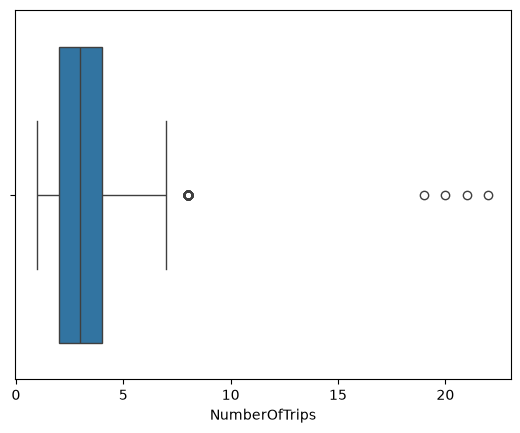

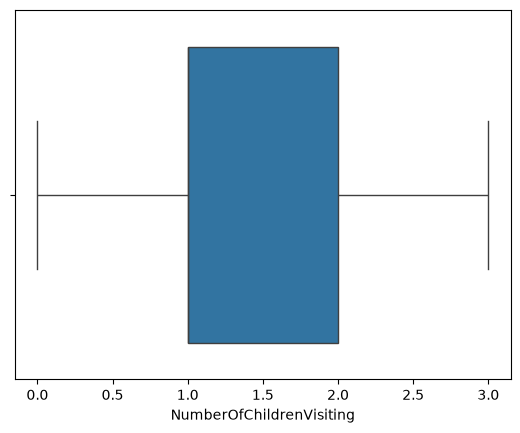

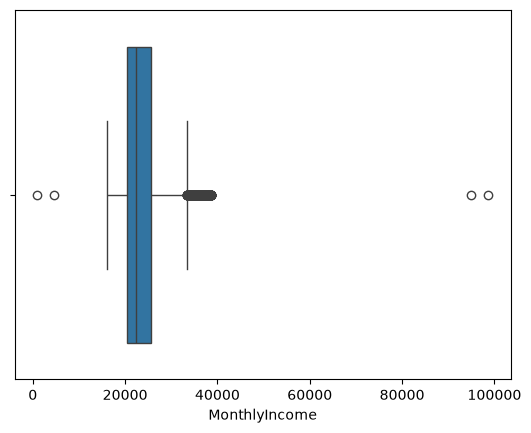

In [23]:
for col in df_numeric.columns:
    plt.figure()
    sns.boxplot(x=df_numeric[col])

In [24]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

df['DurationOfPitch'] = df['DurationOfPitch'].fillna(df['DurationOfPitch'].median())

df['NumberOfFollowups'] = df['NumberOfFollowups'].fillna(df['NumberOfFollowups'].median())

df['TypeofContact'] = df['TypeofContact'].fillna(df['TypeofContact'].mode().iloc[0])

df['PreferredPropertyStar'] = df['PreferredPropertyStar'].fillna(df['PreferredPropertyStar'].mean())

df['NumberOfTrips'] = df['NumberOfTrips'].fillna(df['NumberOfTrips'].mean())

df['NumberOfChildrenVisiting'] = df['NumberOfChildrenVisiting'].fillna(df['NumberOfChildrenVisiting'].mean())

df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())

In [25]:
df.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [26]:
df.drop("CustomerID",axis=1,inplace=True)

In [27]:
df.columns

Index(['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch',
       'Occupation', 'Gender', 'NumberOfPersonVisiting', 'NumberOfFollowups',
       'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus',
       'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar',
       'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='str')

# Feature Engineering


In [28]:
df['TotalVisiting']=df['NumberOfPersonVisiting']+df['NumberOfChildrenVisiting']

In [29]:
df.drop(columns=['NumberOfPersonVisiting', 'NumberOfChildrenVisiting'], inplace=True)

In [30]:
df.columns

Index(['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch',
       'Occupation', 'Gender', 'NumberOfFollowups', 'ProductPitched',
       'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport',
       'PitchSatisfactionScore', 'OwnCar', 'Designation', 'MonthlyIncome',
       'TotalVisiting'],
      dtype='str')

In [31]:
# model Training 

In [32]:
X=df.drop('ProdTaken',axis=1)
y=df['ProdTaken']

In [33]:
from sklearn.model_selection import train_test_split

In [34]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [35]:
#  column Transformer= used to apply differnet prepreocessing technique on different column

In [36]:
from sklearn.compose import ColumnTransformer

In [37]:
cat_feature=X.select_dtypes(include='str').columns
num_feature=X.select_dtypes(exclude='str').columns

In [38]:
cat_feature

Index(['TypeofContact', 'Occupation', 'Gender', 'ProductPitched',
       'MaritalStatus', 'Designation'],
      dtype='str')

In [39]:
num_feature

Index(['Age', 'CityTier', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'Passport',
       'PitchSatisfactionScore', 'OwnCar', 'MonthlyIncome', 'TotalVisiting'],
      dtype='str')

In [40]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [41]:
# create  an object of both preprocessing

In [42]:
numeric_transformer=StandardScaler()
oh_transformer=OneHotEncoder()

In [43]:
preprocessor=ColumnTransformer(
    [
        ("OneHotEncoder",oh_transformer,cat_feature),
        ("StandardScaler",numeric_transformer,num_feature)
    ]
)

In [44]:
# Apply trnasformation on training data 

In [45]:
X_train=preprocessor.fit_transform(X_train)
X_test=preprocessor.transform(X_test)

In [46]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

In [48]:
models={
    "RandomForest":RandomForestClassifier(),
    "Ada boost":AdaBoostClassifier(),
    "Gradient boost":GradientBoostingClassifier(),
    "Decision tree":DecisionTreeClassifier(),
    "Xgboost":XGBClassifier()
}

In [49]:
for i in range (len(list(models))):
    model=list(models.values())[i]
    
    # model trainig
    model.fit(X_train,y_train)
    
    # make prediction
    y_pred_train=model.predict(X_train)
    y_pred_test=model.predict(X_test)
    
    print(list(models.keys())[i])
    
    print("Training accuracy")

    print(f"Accuracy-{accuracy_score(y_train,y_pred_train)}")
    print(f"precision-{precision_score(y_train,y_pred_train)}")
    print(f"recall-{recall_score(y_train,y_pred_train)}")
    print(f"fi-score-{f1_score(y_train,y_pred_train)}")

    print("Testing accuracy")

    print("Accuracy {accuracy_score(y_test,y_prod_test)}")
    print(f"precision-{precision_score(y_test,y_pred_test)}")
    print(f"recall-{recall_score(y_test,y_pred_test)}")
    print(f"f1-score-{f1_score(y_test,y_pred_test)}")
    
    
    print("-------------------------------------------")

RandomForest
Training accuracy
Accuracy-1.0
precision-1.0
recall-1.0
fi-score-1.0
Testing accuracy
Accuracy {accuracy_score(y_test,y_prod_test)}
precision-0.9603174603174603
recall-0.6335078534031413
f1-score-0.7634069400630915
-------------------------------------------
Ada boost
Training accuracy
Accuracy-0.8506393861892583
precision-0.7935222672064778
recall-0.26886145404663925
fi-score-0.4016393442622951
Testing accuracy
Accuracy {accuracy_score(y_test,y_prod_test)}
precision-0.7868852459016393
recall-0.2513089005235602
f1-score-0.38095238095238093
-------------------------------------------
Gradient boost
Training accuracy
Accuracy-0.8936061381074168
precision-0.8735083532219571
recall-0.5020576131687243
fi-score-0.6376306620209059
Testing accuracy
Accuracy {accuracy_score(y_test,y_prod_test)}
precision-0.7731958762886598
recall-0.39267015706806285
f1-score-0.5208333333333334
-------------------------------------------
Decision tree
Training accuracy
Accuracy-1.0
precision-1.0
rec

In [50]:
from sklearn.model_selection import RandomizedSearchCV

In [51]:
xgb_data={
    "n_estimators":[100,200,300,400],
    "max_depth":[3,5,7,100],
    "Learning_rate":[0.1,0.2,0.01,0.05]
        }

In [52]:
xgb_model=XGBClassifier(
    objective="binary:logistic",
    evaluation_metrics="f1_score",
    user_label_encoder=False
)

In [53]:
best_params=RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_data,
    cv=5,
    random_state=42
)

In [54]:
models= {
    "XGboost": XGBClassifier()
}

In [55]:
for i in range(len(list(models))):
    model=list(models.values())[i]

    # model training
    model.fit(X_train,y_train)

    # make prediction
    y_pred_train=model.predict(X_train)
    y_pred_test=model.predict(X_test)

    print(list(models.keys())[i])

    print("Training accuracy")
    print(f"Accuracy={accuracy_score(y_train,y_pred_train)}")
    print(f"precision={precision_score(y_train,y_pred_train)}")
    print(f"recall={recall_score(y_train,y_pred_train)}")
    print(f"f1-score={f1_score(y_train,y_pred_train)}")

    print("Testing accuracy")
    print(f"Accuracy={accuracy_score(y_test,y_pred_test)}")
    print(f"precision={precision_score(y_test,y_pred_test)}")
    print(f"recall={recall_score(y_test,y_pred_test)}")
    print(f"f1-score={f1_score(y_test,y_pred_test)}")

    print("--------------------------------------------------------")

XGboost
Training accuracy
Accuracy=0.9997442455242966
precision=1.0
recall=0.9986282578875172
f1-score=0.9993136582017845
Testing accuracy
Accuracy=0.9366053169734151
precision=0.951048951048951
recall=0.7120418848167539
f1-score=0.8143712574850299
--------------------------------------------------------


In [56]:
import joblib

In [57]:
joblib.dump(preprocessor,'preprocessor.joblib')

['preprocessor.joblib']

In [58]:
joblib.dump(models,'model.joblib')

['model.joblib']